In [1]:
import os, sys, json, time
PROJECT_ROOT = os.path.abspath("..")
sys.path.append(PROJECT_ROOT)

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score, precision_score
from src.data import load_split, make_dataset, CLASSES

train_df, val_df, test_df = load_split(PROJECT_ROOT)
y_val = val_df["label"].values

idx = np.arange(len(CLASSES))
w = compute_class_weight("balanced", classes=idx, y=train_df["label"].values)
class_weight_sqrt = {int(i): float(np.sqrt(x)) for i, x in zip(idx, w)}

IMG_SHAPE = (224, 224, 3)
base = keras.applications.EfficientNetB0(input_shape=IMG_SHAPE, include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG_SHAPE)
x = base(inputs, training=False)          # no Rescaling: Keras EfficientNet expects raw 0-255 and scales internally
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
model = keras.Model(inputs, outputs, name="efficientnetb0_sqrtweights")
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

print("Trainable params:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))
print("Frozen params:", sum(int(np.prod(w.shape)) for w in model.non_trainable_weights))
imgs, labels = next(iter(make_dataset(val_df, batch_size=32)))
print("Output shape:", model.predict(imgs, verbose=0).shape)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 28s 2us/step
Trainable params: 8967
Frozen params: 4049571
Output shape: (32, 7)


In [2]:
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
train_ds = make_dataset(train_df, batch_size=32, training=True)
val_ds = make_dataset(val_df, batch_size=32, training=False)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, "efficientnetb0_head_sqrt.keras"),
                                    monitor="val_loss", save_best_only=True),
]

t0 = time.time()
hist = model.fit(train_ds, validation_data=val_ds, epochs=15,
                 class_weight=class_weight_sqrt, callbacks=callbacks)
print(f"\nTraining time: {(time.time() - t0) / 60:.1f} min")
best_epoch = int(np.argmin(hist.history["val_loss"])) + 1
print("Best epoch:", best_epoch)

val_probs = model.predict(val_ds, verbose=0)
val_pred = val_probs.argmax(axis=1)
res = {"model": "efficientnetb0_frozen_head_sqrt",
       "val_accuracy": float((val_pred == y_val).mean()),
       "val_balanced_accuracy": float(balanced_accuracy_score(y_val, val_pred)),
       "val_macro_f1": float(f1_score(y_val, val_pred, average="macro")),
       "mel_recall": float(recall_score(y_val, val_pred, labels=[4], average=None)[0]),
       "mel_precision": float(precision_score(y_val, val_pred, labels=[4], average=None)[0]),
       "best_epoch": best_epoch}
with open(os.path.join(PROJECT_ROOT, "results", "efficientnetb0_head_sqrt.json"), "w") as f:
    json.dump(res, f, indent=2)
print(json.dumps(res, indent=2))

Epoch 1/15


<project>\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


219/219 ━━━━━━━━━━━━━━━━━━━━ 232s 1s/step - accuracy: 0.6561 - loss: 1.1188 - val_accuracy: 0.6913 - val_loss: 0.9212 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 213s 968ms/step - accuracy: 0.7015 - loss: 0.8905 - val_accuracy: 0.6802 - val_loss: 0.9301 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 215s 977ms/step - accuracy: 0.7165 - loss: 0.8246 - val_accuracy: 0.7265 - val_loss: 0.7906 - learning_rate: 0.0010
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 218s 993ms/step - accuracy: 0.7275 - loss: 0.7806 - val_accuracy: 0.7330 - val_loss: 0.7512 - learning_rate: 0.0010
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 214s 972ms/step - accuracy: 0.7358 - loss: 0.7482 - val_accuracy: 0.7428 - val_loss: 0.7486 - learning_rate: 0.0010
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 219s 999ms/step - accuracy: 0.7442 - loss: 0.7325 - val_accuracy: 0.7239 - val_loss: 0.7624 - learning_rate: 0.0010
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 214s 975ms/step - accuracy: 0.7488 - l

In [3]:
print(json.load(open(os.path.join(PROJECT_ROOT, "results", "efficientnetb0_head_sqrt.json"))))

{'model': 'efficientnetb0_frozen_head_sqrt', 'val_accuracy': 0.7506527415143603, 'val_balanced_accuracy': 0.5869098052102087, 'val_macro_f1': 0.5875974742838143, 'mel_recall': 0.4411764705882353, 'mel_precision': 0.436046511627907, 'best_epoch': 7}


In [4]:
base = next(l for l in model.layers if isinstance(l, keras.Model))
print("Base layers:", len(base.layers))
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
print("Trainable params now:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
    keras.callbacks.ModelCheckpoint(os.path.join(MODELS_DIR, "efficientnetb0_finetuned_sqrt.keras"),
                                    monitor="val_loss", save_best_only=True),
]
t0 = time.time()
hist = model.fit(train_ds, validation_data=val_ds, epochs=15,
                 class_weight=class_weight_sqrt, callbacks=callbacks)
print(f"\nTraining time: {(time.time() - t0) / 60:.1f} min")
best_epoch = int(np.argmin(hist.history["val_loss"])) + 1

val_probs = model.predict(val_ds, verbose=0)
val_pred = val_probs.argmax(axis=1)
res = {"model": "efficientnetb0_finetuned_sqrt",
       "val_accuracy": float((val_pred == y_val).mean()),
       "val_balanced_accuracy": float(balanced_accuracy_score(y_val, val_pred)),
       "val_macro_f1": float(f1_score(y_val, val_pred, average="macro")),
       "mel_recall": float(recall_score(y_val, val_pred, labels=[4], average=None)[0]),
       "mel_precision": float(precision_score(y_val, val_pred, labels=[4], average=None)[0]),
       "best_epoch": best_epoch}
with open(os.path.join(PROJECT_ROOT, "results", "efficientnetb0_finetuned_sqrt.json"), "w") as f:
    json.dump(res, f, indent=2)
print(json.dumps(res, indent=2))

Base layers: 238
Trainable params now: 1492327
Epoch 1/15


<project>\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


219/219 ━━━━━━━━━━━━━━━━━━━━ 253s 1s/step - accuracy: 0.7578 - loss: 0.6702 - val_accuracy: 0.7507 - val_loss: 0.7248 - learning_rate: 1.0000e-05
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 244s 1s/step - accuracy: 0.7582 - loss: 0.6601 - val_accuracy: 0.7454 - val_loss: 0.7128 - learning_rate: 1.0000e-05
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 238s 1s/step - accuracy: 0.7698 - loss: 0.6439 - val_accuracy: 0.7461 - val_loss: 0.7192 - learning_rate: 1.0000e-05
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 235s 1s/step - accuracy: 0.7711 - loss: 0.6283 - val_accuracy: 0.7559 - val_loss: 0.7028 - learning_rate: 1.0000e-05
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 238s 1s/step - accuracy: 0.7675 - loss: 0.6144 - val_accuracy: 0.7598 - val_loss: 0.7015 - learning_rate: 1.0000e-05
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 241s 1s/step - accuracy: 0.7739 - loss: 0.6048 - val_accuracy: 0.7520 - val_loss: 0.7082 - learning_rate: 1.0000e-05
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 241s 1s/step - accuracy: 0.77

In [5]:
print(json.load(open(os.path.join(PROJECT_ROOT, "results", "efficientnetb0_finetuned_sqrt.json"))))

{'model': 'efficientnetb0_finetuned_sqrt', 'val_accuracy': 0.7741514360313316, 'val_balanced_accuracy': 0.6307668125676128, 'val_macro_f1': 0.6096377775043219, 'mel_recall': 0.4588235294117647, 'mel_precision': 0.4482758620689655, 'best_epoch': 13}


              precision    recall  f1-score   support

       akiec      0.423     0.588     0.492        51
         bcc      0.558     0.688     0.616        77
         bkl      0.567     0.618     0.591       157
          df      0.667     0.316     0.429        19
         mel      0.448     0.459     0.453       170
          nv      0.917     0.871     0.893      1034
        vasc      0.724     0.875     0.792        24

    accuracy                          0.774      1532
   macro avg      0.615     0.631     0.610      1532
weighted avg      0.788     0.774     0.779      1532



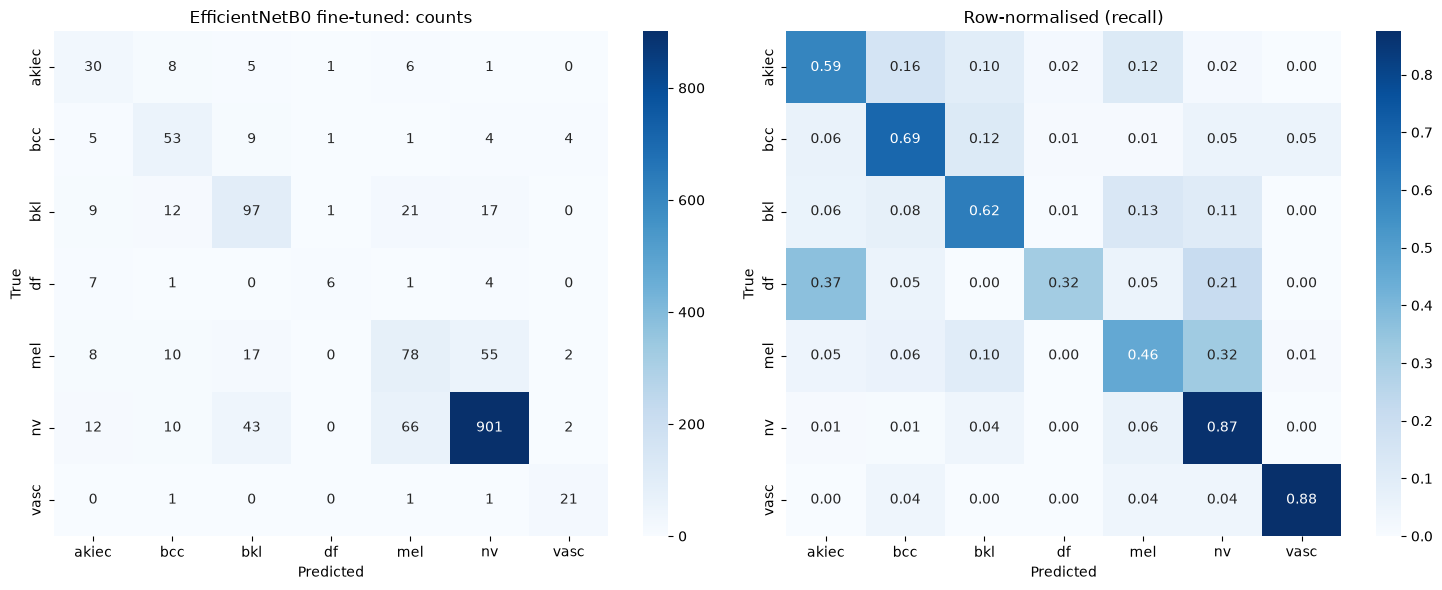

threshold | mel recall | mel precision | flagged
     0.50 |      0.388 |         0.520 | 127
     0.40 |      0.453 |         0.440 | 175
     0.30 |      0.565 |         0.360 | 267
     0.25 |      0.600 |         0.323 | 316
     0.20 |      0.688 |         0.292 | 401
     0.15 |      0.729 |         0.254 | 489
     0.10 |      0.835 |         0.230 | 617


In [6]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print(classification_report(y_val, val_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_val, val_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("EfficientNetB0 fine-tuned: counts")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Row-normalised (recall)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.show()

mel_p = val_probs[:, 4]
is_mel = (y_val == 4).astype(int)
print("threshold | mel recall | mel precision | flagged")
for t in [0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]:
    pm = mel_p >= t
    tp = (pm & (is_mel == 1)).sum()
    print(f"{t:9.2f} | {tp / is_mel.sum():10.3f} | {tp / max(pm.sum(), 1):13.3f} | {pm.sum()}")

In [7]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

test_ds = make_dataset(test_df, batch_size=32, training=False)
y_test = test_df["label"].values
test_probs = model.predict(test_ds, verbose=0)
test_pred = test_probs.argmax(axis=1)

print(classification_report(y_test, test_pred, target_names=CLASSES, digits=3))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, test_pred), 4))
print(confusion_matrix(y_test, test_pred))
for i, c in enumerate(CLASSES):
    print(f"ROC-AUC {c:6s}: {roc_auc_score((y_test == i).astype(int), test_probs[:, i]):.3f}")

pm = test_probs[:, 4] >= 0.25
is_mel = (y_test == 4)
print("mel @0.25 -> recall", round((pm & is_mel).sum() / is_mel.sum(), 3),
      "precision", round((pm & is_mel).sum() / max(pm.sum(), 1), 3), "flagged", pm.sum())

              precision    recall  f1-score   support

       akiec      0.375     0.522     0.436        46
         bcc      0.473     0.620     0.537        71
         bkl      0.541     0.548     0.544       168
          df      0.500     0.450     0.474        20
         mel      0.468     0.491     0.479       165
          nv      0.933     0.885     0.908       992
        vasc      0.682     0.789     0.732        19

    accuracy                          0.772      1481
   macro avg      0.567     0.615     0.587      1481
weighted avg      0.788     0.772     0.779      1481

Balanced accuracy: 0.6149
[[ 24  11   6   1   3   1   0]
 [  7  44   8   2   2   8   0]
 [ 11  13  92   2  30  20   0]
 [  2   3   4   9   0   2   0]
 [ 10   7  34   1  81  30   2]
 [ 10  14  26   2  57 878   5]
 [  0   1   0   1   0   2  15]]
ROC-AUC akiec : 0.953
ROC-AUC bcc   : 0.957
ROC-AUC bkl   : 0.902
ROC-AUC df    : 0.964
ROC-AUC mel   : 0.847
ROC-AUC nv    : 0.944
ROC-AUC vasc  : 0.975
mel @

In [8]:
model.save(os.path.join(PROJECT_ROOT, "models", "final_efficientnetb0.keras"))
json.dump({"mel_threshold": 0.25, "classes": CLASSES}, open(os.path.join(PROJECT_ROOT, "models", "final_config.json"), "w"))

In [9]:
base = next(l for l in model.layers if isinstance(l, keras.Model))
print([l.name for l in base.layers[-6:]])
print([l.name for l in model.layers])

['block7a_se_excite', 'block7a_project_conv', 'block7a_project_bn', 'top_conv', 'top_bn', 'top_activation']
['input_layer_1', 'efficientnetb0', 'global_average_pooling2d', 'dropout', 'dense']


In [10]:
model.save(os.path.join(PROJECT_ROOT, "models", "final_efficientnetb0.keras"))
json.dump({"mel_threshold": 0.25, "classes": CLASSES},
          open(os.path.join(PROJECT_ROOT, "models", "final_config.json"), "w"))
print(os.path.exists(os.path.join(PROJECT_ROOT, "models", "final_efficientnetb0.keras")))

True


Max difference vs model.predict: 2.384185791015625e-07


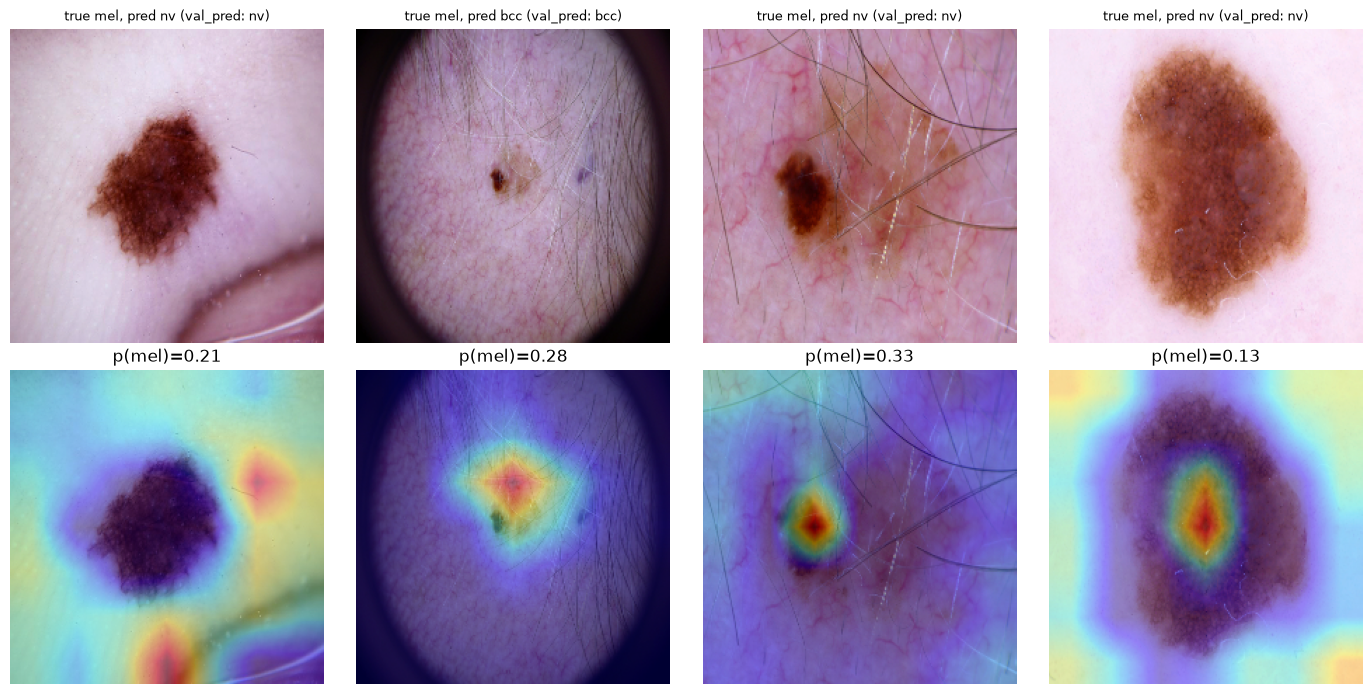

In [11]:
import cv2
import matplotlib.pyplot as plt

base = model.get_layer("efficientnetb0")
feat_model = keras.Model(base.input, base.get_layer("top_activation").output)
gap, drop, dense = (model.get_layer(n) for n in ["global_average_pooling2d", "dropout", "dense"])

def load_like_pipeline(path):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.image.resize(img, (224, 224)).numpy()   # raw 0-255, same as training

def gradcam(img, class_idx=None):
    x = tf.convert_to_tensor(img[None].astype("float32"))   # NO rescaling: EfficientNet scales internally
    with tf.GradientTape() as tape:
        fmap = feat_model(x, training=False)
        tape.watch(fmap)
        probs = dense(drop(gap(fmap), training=False))
        if class_idx is None:
            class_idx = int(tf.argmax(probs[0]))
        score = probs[0, class_idx]
    grads = tape.gradient(score, fmap)
    wts = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fmap * wts[:, None, None, :], axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return cv2.resize(cam, (224, 224)), class_idx, probs[0].numpy()

# Sanity check: our rebuilt forward pass must match model.predict
img0 = load_like_pipeline(val_df["abs_path"].iloc[0])
_, _, p_cam = gradcam(img0)
p_ref = model.predict(img0[None], verbose=0)[0]
print("Max difference vs model.predict:", float(np.abs(p_cam - p_ref).max()))

# Missed melanomas (true mel, pipeline-predicted otherwise), as before
val_probs = model.predict(make_dataset(val_df, batch_size=32), verbose=0)
val_pred = val_probs.argmax(axis=1)
miss = np.where((y_val == 4) & (val_pred != 4))[0][:4]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, i in enumerate(miss):
    img = load_like_pipeline(val_df["abs_path"].iloc[i])
    cam, pred, probs = gradcam(img)
    axes[0, k].imshow(img.astype("uint8")); axes[0, k].axis("off")
    axes[0, k].set_title(f"true mel, pred {CLASSES[pred]} (val_pred: {CLASSES[val_pred[i]]})", fontsize=9)
    axes[1, k].imshow(img.astype("uint8")); axes[1, k].imshow(cam, cmap="jet", alpha=0.4); axes[1, k].axis("off")
    axes[1, k].set_title(f"p(mel)={probs[4]:.2f}")
plt.tight_layout(); plt.show()

Model loaded successfully!
Test samples: 1481
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
47/47 ━━━━━━━━━━━━━━━━━━━━ 43s 858ms/step

OVERALL TEST PERFORMANCE


,Metric,Score
0,Accuracy,0.7718
1,Balanced Accuracy,0.6149



CLASSIFICATION REPORT


,precision,recall,f1-score,support
akiec,0.3750,0.5217,0.4364,46.0000
bcc,0.4731,0.6197,0.5366,71.0000
bkl,0.5412,0.5476,0.5444,168.0000
df,0.5000,0.4500,0.4737,20.0000
mel,0.4682,0.4909,0.4793,165.0000
nv,0.9330,0.8851,0.9084,992.0000
vasc,0.6818,0.7895,0.7317,19.0000
accuracy,0.7718,0.7718,0.7718,0.7718
macro avg,0.5675,0.6149,0.5872,1481.0000
weighted avg,0.7884,0.7718,0.7787,1481.0000


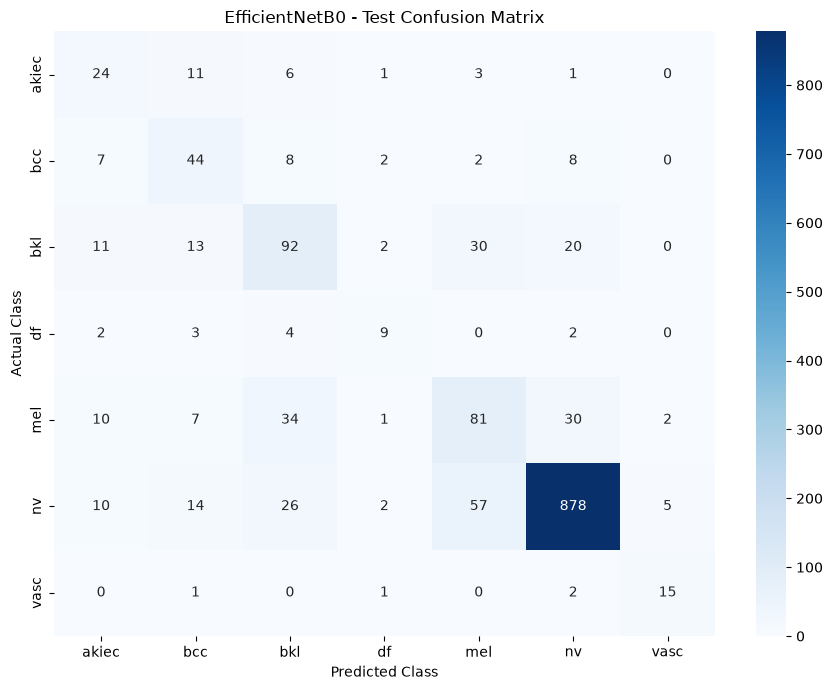

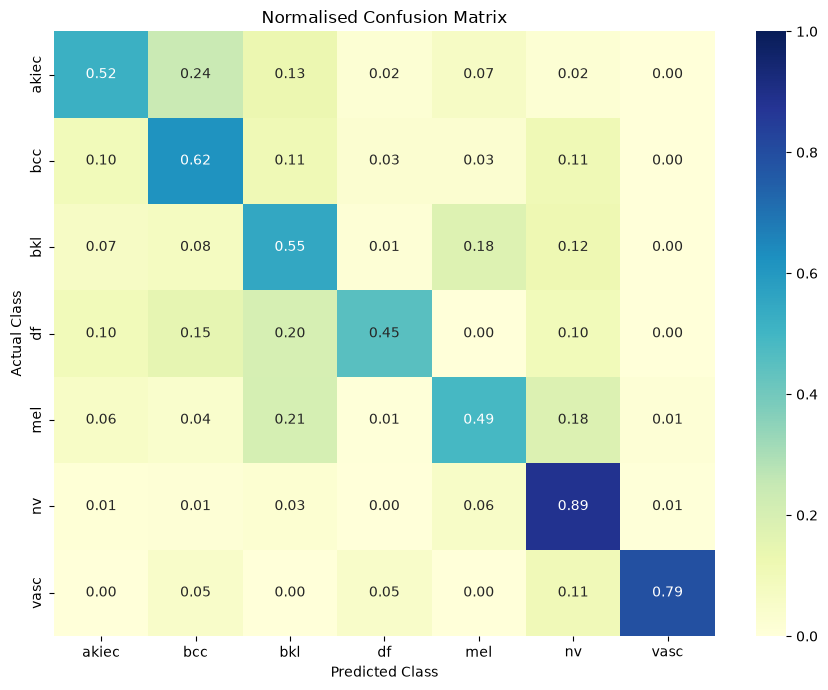

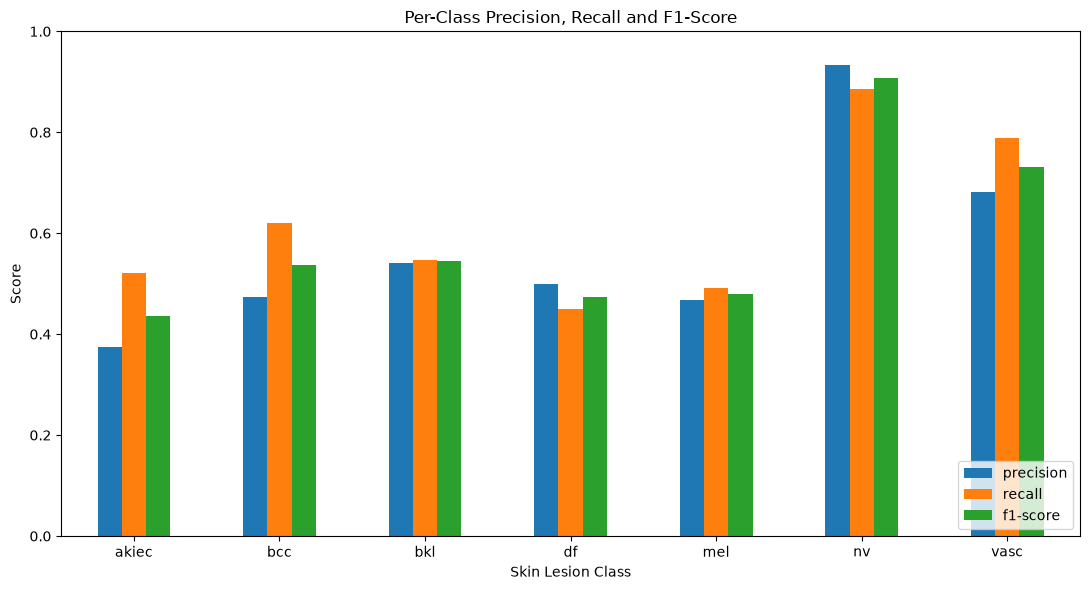

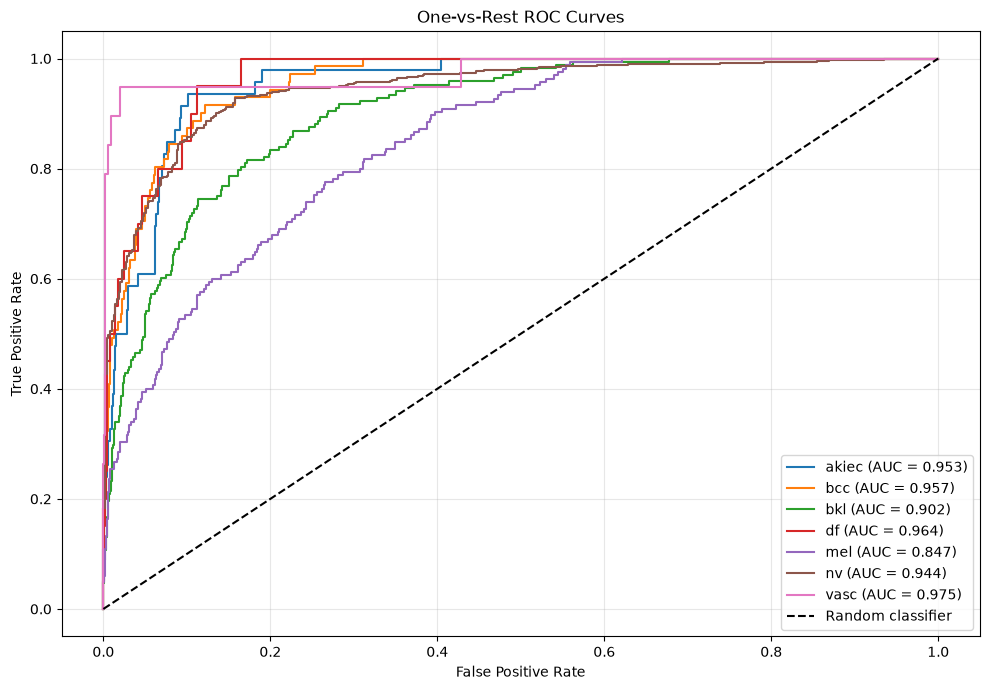


PER-CLASS ROC-AUC SCORES


,Class,ROC-AUC
0,akiec,0.9529
1,bcc,0.9566
2,bkl,0.9022
3,df,0.9641
4,mel,0.8470
5,nv,0.9441
6,vasc,0.9749



MELANOMA THRESHOLD ANALYSIS


,Threshold,Melanoma Recall,Melanoma Precision,Flagged Images
0,0.50,0.3758,0.5210,119
1,0.40,0.4485,0.4458,166
2,0.30,0.5758,0.3815,249
3,0.25,0.6121,0.3311,305
4,0.20,0.6727,0.2968,374
5,0.15,0.7576,0.2706,462
6,0.10,0.8242,0.2390,569


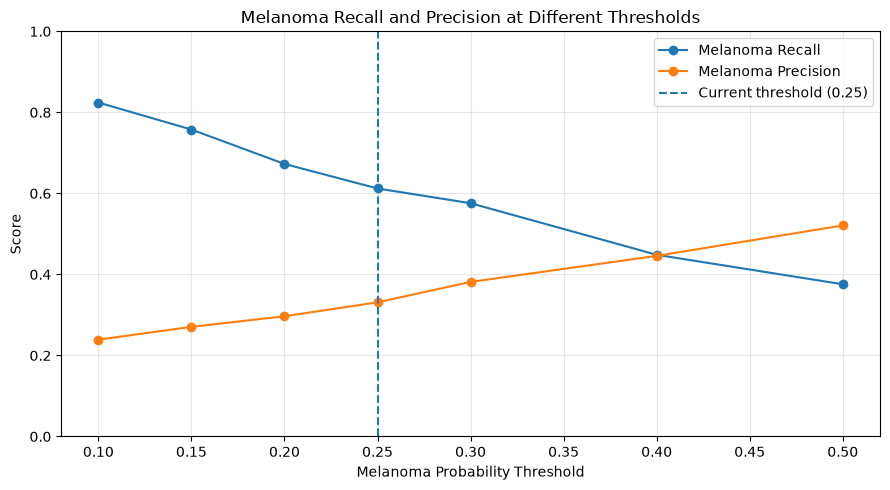


FINAL EVALUATION COMPLETED!


In [5]:

# ============================================================
# FINAL MODEL EVALUATION - EFFICIENTNETB0
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    roc_curve
)
from sklearn.preprocessing import label_binarize

from src.data import load_split, make_dataset, CLASSES

# ------------------------------------------------------------
# 1. LOAD PROJECT DATA AND SAVED MODEL
# ------------------------------------------------------------

PROJECT_ROOT = os.path.abspath("..")

train_df, val_df, test_df = load_split(PROJECT_ROOT)

model_path = os.path.join(
    PROJECT_ROOT, "models", "final_efficientnetb0.keras"
)

model = keras.models.load_model(model_path)

print("Model loaded successfully!")
print("Test samples:", len(test_df))
print("Classes:", CLASSES)

# ------------------------------------------------------------
# 2. GENERATE TEST PREDICTIONS
# ------------------------------------------------------------

test_ds = make_dataset(
    test_df,
    batch_size=32,
    training=False
)

y_test = test_df["label"].values

test_probs = model.predict(test_ds, verbose=1)
test_pred = np.argmax(test_probs, axis=1)

# ------------------------------------------------------------
# 3. OVERALL PERFORMANCE SUMMARY
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, test_pred)
balanced_acc = balanced_accuracy_score(y_test, test_pred)

summary = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced Accuracy"],
    "Score": [accuracy, balanced_acc]
})

print("\nOVERALL TEST PERFORMANCE")
display(summary.round(4))

# ------------------------------------------------------------
# 4. CLASSIFICATION REPORT TABLE
# ------------------------------------------------------------

report = classification_report(
    y_test,
    test_pred,
    target_names=CLASSES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

print("\nCLASSIFICATION REPORT")
display(report_df.round(4))

# ------------------------------------------------------------
# 5. CONFUSION MATRIX - RAW COUNTS
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=np.arange(len(CLASSES))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("EfficientNetB0 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. NORMALISED CONFUSION MATRIX
# ------------------------------------------------------------

cm_norm = cm.astype("float") / np.maximum(
    cm.sum(axis=1, keepdims=True), 1
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    vmin=0,
    vmax=1
)

plt.title("Normalised Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. PER-CLASS PRECISION, RECALL AND F1-SCORE GRAPH
# ------------------------------------------------------------

class_metrics = report_df.loc[CLASSES, [
    "precision", "recall", "f1-score"
]]

ax = class_metrics.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Per-Class Precision, Recall and F1-Score")
plt.xlabel("Skin Lesion Class")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. ROC-AUC SCORES FOR EACH CLASS
# ------------------------------------------------------------

y_test_binary = label_binarize(
    y_test,
    classes=np.arange(len(CLASSES))
)

roc_results = []

plt.figure(figsize=(10, 7))

for i, class_name in enumerate(CLASSES):

    auc_score = roc_auc_score(
        y_test_binary[:, i],
        test_probs[:, i]
    )

    fpr, tpr, _ = roc_curve(
        y_test_binary[:, i],
        test_probs[:, i]
    )

    roc_results.append({
        "Class": class_name,
        "ROC-AUC": auc_score
    })

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {auc_score:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.title("One-vs-Rest ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

roc_df = pd.DataFrame(roc_results)

print("\nPER-CLASS ROC-AUC SCORES")
display(roc_df.round(4))

# ------------------------------------------------------------
# 9. MELANOMA THRESHOLD ANALYSIS
# ------------------------------------------------------------

MEL_IDX = CLASSES.index("mel")

mel_probs = test_probs[:, MEL_IDX]
actual_mel = (y_test == MEL_IDX)

thresholds = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10]

threshold_results = []

for threshold in thresholds:

    predicted_mel = mel_probs >= threshold

    tp = np.sum(predicted_mel & actual_mel)
    fn = np.sum(~predicted_mel & actual_mel)
    fp = np.sum(predicted_mel & ~actual_mel)

    recall = tp / max(tp + fn, 1)
    precision = tp / max(tp + fp, 1)

    threshold_results.append({
        "Threshold": threshold,
        "Melanoma Recall": recall,
        "Melanoma Precision": precision,
        "Flagged Images": int(predicted_mel.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

print("\nMELANOMA THRESHOLD ANALYSIS")
display(threshold_df.round(4))

# ------------------------------------------------------------
# 10. MELANOMA RECALL AND PRECISION GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Melanoma Recall"],
    marker="o",
    label="Melanoma Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Melanoma Precision"],
    marker="o",
    label="Melanoma Precision"
)

plt.axvline(
    0.25,
    linestyle="--",
    label="Current threshold (0.25)"
)

plt.title("Melanoma Recall and Precision at Different Thresholds")
plt.xlabel("Melanoma Probability Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nFINAL EVALUATION COMPLETED!")


In [2]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders here:")
print(os.listdir())

Current working directory:
<project>\notebooks

Files and folders here:
['01_data_exploration.ipynb', '02_pipeline_check.ipynb', '03_baseline_mobilenet.ipynb', '04_finetune.ipynb', '05_finetune_aug2.ipynb', '06_efficientnet.ipynb', '07_ood_gate.ipynb']


In [3]:
import os
import sys

PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)
print("Project root exists:", os.path.exists(PROJECT_ROOT))
print("src folder exists:", os.path.exists(os.path.join(PROJECT_ROOT, "src")))
print("data.py exists:", os.path.exists(os.path.join(PROJECT_ROOT, "src", "data.py")))

Project root: <project>
Project root exists: True
src folder exists: True
data.py exists: True


In [4]:
from src.data import load_split, make_dataset, CLASSES

print("Import successful!")
print("Classes:", CLASSES)

Import successful!
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
